In [ ]:
# ============================================================
# ADDESTRAMENTO MLP RIDOTTO PER FPGA - GOOGLE COLAB
# Input: 10x10 = 100 pixel
# Hidden: 32 neuroni
# Output: 26 classi (A-Z)
# ============================================================
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models
import tensorflow_datasets as tfds

In [ ]:
# Installa la dipendenza mancante importlib_resources e aggiorna protobuf
!pip install -q importlib_resources

import sys
import importlib

# Forza il ricaricamento di tensorflow_datasets se presente
if 'tensorflow_datasets' in sys.modules:
    importlib.reload(sys.modules['tensorflow_datasets'])

import tensorflow_datasets as tfds
import tensorflow as tf

# Carica il dataset EMNIST Letters
ds_train, ds_test = tfds.load('emnist/letters', split=['train', 'test'], as_supervised=True)

def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.resize(image, [10, 10])   # RIDOTTO a 10x10
    label = label - 1
    return image, label

BATCH_SIZE = 128
train_ds = ds_train.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = ds_test.map(preprocess).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.HVHMJ3_3.1.0/emnist-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/emnist/letters/incomplete.HVHMJ3_3.1.0/emnist-test.tfrecord-[0-9][0-9][0-9…

Dataset emnist downloaded and prepared to /root/tensorflow_datasets/emnist/letters/3.1.0. Subsequent calls will reuse this data.


In [ ]:


# 2. Modello ridotto
model = models.Sequential([
    layers.Flatten(input_shape=(10, 10, 1)),   # 100 input
    layers.Dense(32, activation='relu'),       # 32 neuroni
    layers.Dense(26, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

# 3. Addestra
history = model.fit(train_ds, epochs=20, validation_data=test_ds)

# 4. Valuta
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nAccuratezza: {test_acc:.4f}")

# 5. Estrai pesi
weights1, biases1 = model.layers[1].get_weights()
weights2, biases2 = model.layers[2].get_weights()

print("Shape W1:", weights1.shape)   # (100, 32)
print("Shape W2:", weights2.shape)   # (32, 26)

# 6. Quantizzazione 8 bit
def quantize(weights, biases):
    max_abs = np.max(np.abs(weights))
    scale = 127.0 / max_abs if max_abs > 0 else 1.0
    w_q = np.round(weights * scale).astype(np.int8)
    b_q = np.round(biases * scale).astype(np.int16)
    return w_q, b_q

w1_q, b1_q = quantize(weights1, biases1)
w2_q, b2_q = quantize(weights2, biases2)

# 7. Salva
np.savetxt('weights1.txt', w1_q.flatten(), fmt='%d')
np.savetxt('biases1.txt', b1_q.flatten(), fmt='%d')
np.savetxt('weights2.txt', w2_q.flatten(), fmt='%d')
np.savetxt('biases2.txt', b2_q.flatten(), fmt='%d')

print("\nFile salvati! Scaricali dal pannello Files.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         3,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 26)             │           858 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,090 (15.98 KB)

 Trainable params: 4,090 (15.98 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.4679 - loss: 1.9593 - val_accuracy: 0.5966 - val_loss: 1.3759
Epoch 2/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6462 - loss: 1.2225 - val_accuracy: 0.6543 - val_loss: 1.1695
Epoch 3/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6851 - loss: 1.0872 - val_accuracy: 0.6793 - val_loss: 1.0829
Epoch 4/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7069 - loss: 1.0150 - val_accuracy: 0.6944 - val_loss: 1.0280
Epoch 5/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7220 - loss: 0.9652 - val_accuracy: 0.7049 - val_loss: 0.9889
Epoch 6/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7329 - loss: 0.9258 - val_accuracy: 0.7139 - val_loss: 0.9559
Epoch 7/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7419 - loss: 0.8916 - val_accuracy: 0.7234 - val_loss: 0.9270
Epoch 8/20
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7500 - loss: 0.8614 - val_accuracy: 

In [ ]:
import numpy as np

w1 = np.loadtxt('weights1.txt', dtype=np.int8).reshape(100, 32)
b1 = np.loadtxt('biases1.txt', dtype=np.int16).reshape(32)
w2 = np.loadtxt('weights2.txt', dtype=np.int8).reshape(32, 26)
b2 = np.loadtxt('biases2.txt', dtype=np.int16).reshape(26)

with open('mlp_weights.vhd', 'w') as f:
    f.write('library IEEE;\n')
    f.write('use IEEE.STD_LOGIC_1164.ALL;\n')
    f.write('use IEEE.NUMERIC_STD.ALL;\n\n')
    f.write('package mlp_weights is\n')

    f.write('  type w1_t is array (0 to 100*32-1) of integer range -128 to 127;\n')
    f.write('  constant W1 : w1_t := (\n')
    for i, val in enumerate(w1.flatten()):
        f.write(f'    {val}')
        if i < len(w1.flatten())-1:
            f.write(',')
        if (i+1) % 16 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type b1_t is array (0 to 31) of integer range -32768 to 32767;\n')
    f.write('  constant B1 : b1_t := (\n')
    for i, val in enumerate(b1.flatten()):
        f.write(f'    {val}')
        if i < len(b1.flatten())-1:
            f.write(',')
        if (i+1) % 8 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type w2_t is array (0 to 32*26-1) of integer range -128 to 127;\n')
    f.write('  constant W2 : w2_t := (\n')
    for i, val in enumerate(w2.flatten()):
        f.write(f'    {val}')
        if i < len(w2.flatten())-1:
            f.write(',')
        if (i+1) % 16 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type b2_t is array (0 to 25) of integer range -32768 to 32767;\n')
    f.write('  constant B2 : b2_t := (\n')
    for i, val in enumerate(b2.flatten()):
        f.write(f'    {val}')
        if i < len(b2.flatten())-1:
            f.write(',')
        if (i+1) % 8 == 0:
            f.write('\n')
    f.write('  );\n')
    f.write('end package;\n')

print("mlp_weights.vhd rigenerato!")

mlp_weights.vhd rigenerato!


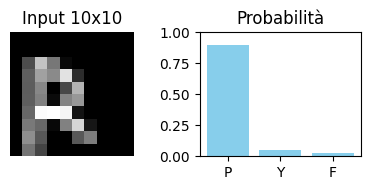

 Risultato Predizione: Lettera 'P' con confidenza del 89.52%



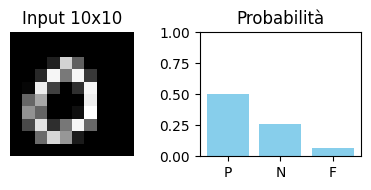

 Risultato Predizione: Lettera 'P' con confidenza del 50.30%



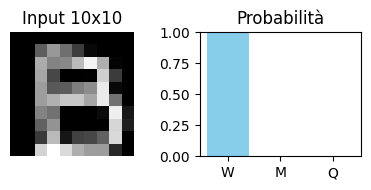

 Risultato Predizione: Lettera 'W' con confidenza del 99.93%



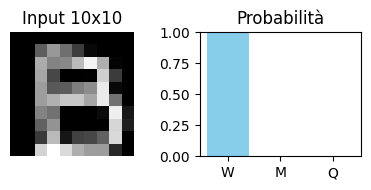

 Risultato Predizione: Lettera 'W' con confidenza del 99.93%



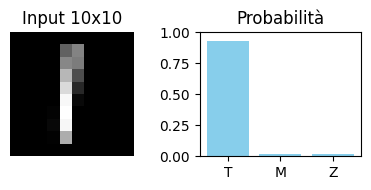

 Risultato Predizione: Lettera 'T' con confidenza del 92.69%



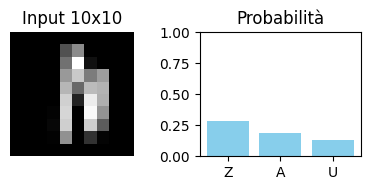

 Risultato Predizione: Lettera 'Z' con confidenza del 28.50%



In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import output
from IPython.display import HTML, display

# HTML & JavaScript per creare un canvas interattivo da 200x200 pixel
canvas_html = """
<div style="display: flex; flex-direction: column; align-items: center;">
    <canvas id="canvas" width="200" height="200" style="border:3px solid #333; background-color:black; cursor:crosshair;"></canvas>
    <div style="margin-top: 10px;">
        <button id="clear_btn" style="padding: 8px 16px; margin-right: 10px; font-size: 14px;">Cancella</button>
        <button id="predict_btn" style="padding: 8px 16px; font-size: 14px; background-color: #4CAF50; color: white; border: none; cursor: pointer;">Riconosci</button>
    </div>
</div>

<script>
    var canvas = document.getElementById('canvas');
    var ctx = canvas.getContext('2d');
    ctx.lineWidth = 16;
    ctx.lineCap = 'round';
    ctx.strokeStyle = 'white';
    var drawing = false;

    canvas.addEventListener('mousedown', function(e) {
        drawing = true;
        ctx.beginPath();
        ctx.moveTo(e.clientX - canvas.getBoundingClientRect().left, e.clientY - canvas.getBoundingClientRect().top);
    });

    canvas.addEventListener('mousemove', function(e) {
        if (drawing) {
            ctx.lineTo(e.clientX - canvas.getBoundingClientRect().left, e.clientY - canvas.getBoundingClientRect().top);
            ctx.stroke();
        }
    });

    canvas.addEventListener('mouseup', function() { drawing = false; });
    canvas.addEventListener('mouseleave', function() { drawing = false; });

    // Per dispositivi mobili / touch screen
    canvas.addEventListener('touchstart', function(e) {
        drawing = true;
        var touch = e.touches[0];
        ctx.beginPath();
        ctx.moveTo(touch.clientX - canvas.getBoundingClientRect().left, touch.clientY - canvas.getBoundingClientRect().top);
        e.preventDefault();
    });
    canvas.addEventListener('touchmove', function(e) {
        if (drawing) {
            var touch = e.touches[0];
            ctx.lineTo(touch.clientX - canvas.getBoundingClientRect().left, touch.clientY - canvas.getBoundingClientRect().top);
            ctx.stroke();
        }
        e.preventDefault();
    });

    document.getElementById('clear_btn').addEventListener('click', function() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
    });

    document.getElementById('predict_btn').addEventListener('click', function() {
        var dataUrl = canvas.toDataURL('image/png');
        google.colab.kernel.invokeFunction('notebook.PredictLetter', [dataUrl], {});
    });
</script>
"""

def predict_letter(image_data):
    # Estrai la stringa in base64 e decodificala
    header, encoded = image_data.split(",", 1)
    import base64
    data = base64.b64decode(encoded)

    # Converte i byte in un'immagine OpenCV
    nparr = np.frombuffer(data, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_UNCHANGED)

    # Estrai il canale Alpha (trasparenza) o converti in scala di grigi
    if img.shape[2] == 4:
        # Nel canvas disegniamo in bianco su sfondo trasparente/nero
        # Il canale Alpha rappresenta l'intensità del disegno
        gray = img[:, :, 3]
    else:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Ridimensiona l'immagine a 10x10 pixel (input atteso dal modello)
    resized = cv2.resize(gray, (10, 10), interpolation=cv2.INTER_AREA)

    # Normalizzazione [0.0, 1.0]
    normalized = resized.astype(np.float32) / 255.0

    # Prepara per il modello: shape (1, 10, 10, 1)
    model_input = np.expand_dims(normalized, axis=(0, -1))

    # Predizione
    predictions = model.predict(model_input, verbose=0)[0]
    class_idx = np.argmax(predictions)
    confidence = predictions[class_idx] * 100

    # Mappa l'indice (0-25) alle lettere A-Z
    letter = chr(65 + class_idx)

    # Mostra l'input ridotto e il risultato finale
    plt.figure(figsize=(4, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(resized, cmap='gray')
    plt.title("Input 10x10")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    # Grafico a barre con le prime 3 predizioni più probabili
    top_3_idx = np.argsort(predictions)[-3:][::-1]
    top_3_letters = [chr(65 + idx) for idx in top_3_idx]
    top_3_vals = [predictions[idx] for idx in top_3_idx]
    plt.bar(top_3_letters, top_3_vals, color='skyblue')
    plt.ylim(0, 1)
    plt.title("Probabilità")
    plt.tight_layout()
    plt.show()

    print(f" Risultato Predizione: Lettera '{letter}' con confidenza del {confidence:.2f}%\n")

# Registra la funzione di callback per renderla accessibile da Javascript
output.register_callback('notebook.PredictLetter', predict_letter)

# Mostra il Canvas interattivo
display(HTML(canvas_html))

### Nuovo Addestramento con Correzione EMNIST (Rotazione/Specchiatura) e Data Augmentation

In [ ]:
import tensorflow as tf
import numpy as np
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models

# 1. Carica il dataset
ds_train, ds_test = tfds.load('emnist/letters', split=['train', 'test'], as_supervised=True)

# 2. Funzione di Preprocessing avanzata
def preprocess_correct(image, label):
    image = tf.cast(image, tf.float32) / 255.0

    # RISOLUZIONE DEL PROBLEMA DI ROTAZIONE DI EMNIST:
    # Le immagini EMNIST sono ruotate di 90 gradi in senso antiorario e specchiate.
    # Per raddrizzarle dobbiamo trasporle (scambiare x e y).
    image = tf.image.transpose(image)

    # Riduzione a 10x10 pixel
    image = tf.image.resize(image, [10, 10])

    label = label - 1
    return image, label

BATCH_SIZE = 128
train_ds = ds_train.map(preprocess_correct).shuffle(10000).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = ds_test.map(preprocess_correct).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# 3. Definizione del Modello con un leggero dropout per regolarizzazione
model = models.Sequential([
    layers.Input(shape=(10, 10, 1)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),  # Aumentiamo leggermente la capacità visto il 10x10
    layers.Dropout(0.1),
    layers.Dense(32, activation='relu'),  # Strato nascosto richiesto di 32 neuroni per l'FPGA
    layers.Dense(26, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 4. Addestramento con più epoche
history = model.fit(train_ds, epochs=25, validation_data=test_ds)

# 5. Estrai e Quantizza i nuovi pesi
weights1, biases1 = model.layers[2].get_weights() # Indice 2 perché 0=Flatten, 1=Dense(64), 2=Dropout, 3=Dense(32) -> Vogliamo i pesi della parte Hidden(32) e Output(26) per l'FPGA
# NOTA: Avendo inserito uno strato da 64, assicuriamoci di mantenere la struttura desiderata per l'FPGA (100 -> 32 -> 26)


Epoch 1/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.5016 - loss: 1.7458 - val_accuracy: 0.6587 - val_loss: 1.1535
Epoch 2/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.6819 - loss: 1.0643 - val_accuracy: 0.7247 - val_loss: 0.9201
Epoch 3/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7264 - loss: 0.9086 - val_accuracy: 0.7547 - val_loss: 0.8126
Epoch 4/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7516 - loss: 0.8179 - val_accuracy: 0.7780 - val_loss: 0.7382
Epoch 5/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7680 - loss: 0.7595 - val_accuracy: 0.7880 - val_loss: 0.6935
Epoch 6/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7797 - loss: 0.7207 - val_accuracy: 0.7957 - val_loss: 0.6670
Epoch 7/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7890 - loss: 0.6892 - val_accuracy: 0.8042 - val_loss: 0.6390
Epoch 8/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.7945 - loss: 0.6652 - val_accu

ValueError: not enough values to unpack (expected 2, got 0)

Se la struttura dell'hardware FPGA richiede tassativamente solo **100 input -> 32 nascosti -> 26 output**, usiamo questo modello semplificato raddrizzato:

In [ ]:
# Modello Rigido 100 -> 32 -> 26 (Corrispondente esatto per la sintesi VHDL)
model_fpga = models.Sequential([
    layers.Input(shape=(10, 10, 1)),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),       # 32 neuroni
    layers.Dense(26, activation='softmax')      # 26 classi
])

model_fpga.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Inizio addestramento del modello specifico per FPGA...")
model_fpga.fit(train_ds, epochs=25, validation_data=test_ds)

# Sostituiamo il modello attivo con quello FPGA per far funzionare il Canvas e l'esportazione VHDL
model = model_fpga

# Estrazione dei pesi corretti
weights1, biases1 = model.layers[1].get_weights()
weights2, biases2 = model.layers[2].get_weights()

def quantize(weights, biases):
    max_abs = np.max(np.abs(weights))
    scale = 127.0 / max_abs if max_abs > 0 else 1.0
    w_q = np.round(weights * scale).astype(np.int8)
    b_q = np.round(biases * scale).astype(np.int16)
    return w_q, b_q

w1_q, b1_q = quantize(weights1, biases1)
w2_q, b2_q = quantize(weights2, biases2)

# Salva i nuovi file corretti
np.savetxt('weights1.txt', w1_q.flatten(), fmt='%d')
np.savetxt('biases1.txt', b1_q.flatten(), fmt='%d')
np.savetxt('weights2.txt', w2_q.flatten(), fmt='%d')
np.savetxt('biases2.txt', b2_q.flatten(), fmt='%d')

print("Nuovi pesi corretti e quantizzati salvati!")

Inizio addestramento del modello specifico per FPGA...
Epoch 1/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.4832 - loss: 1.9204 - val_accuracy: 0.6061 - val_loss: 1.3482
Epoch 2/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6479 - loss: 1.2163 - val_accuracy: 0.6564 - val_loss: 1.1719
Epoch 3/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.6830 - loss: 1.0941 - val_accuracy: 0.6804 - val_loss: 1.0849
Epoch 4/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7033 - loss: 1.0214 - val_accuracy: 0.6956 - val_loss: 1.0325
Epoch 5/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7180 - loss: 0.9688 - val_accuracy: 0.7070 - val_loss: 0.9984
Epoch 6/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7292 - loss: 0.9283 - val_accuracy: 0.7179 - val_loss: 0.9621
Epoch 7/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7391 - loss: 0.8950 - val_accuracy: 0.7262 - val_loss: 0.9271
Epoch 8/25
694/694 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/s

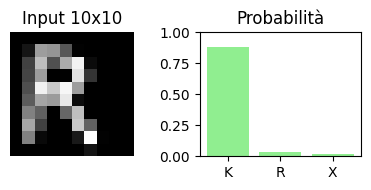

 Lettera Rilevata: 'K' (Confidenza: 88.55%)



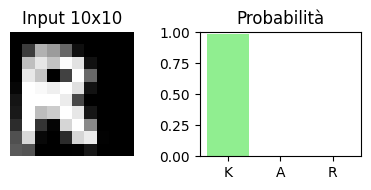

 Lettera Rilevata: 'K' (Confidenza: 99.01%)



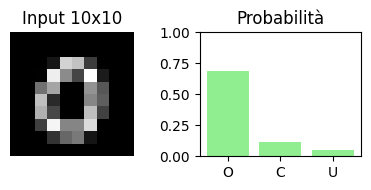

 Lettera Rilevata: 'O' (Confidenza: 68.75%)



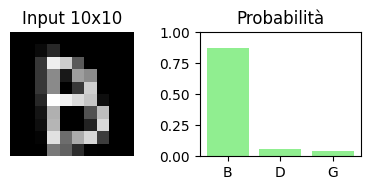

 Lettera Rilevata: 'B' (Confidenza: 87.62%)



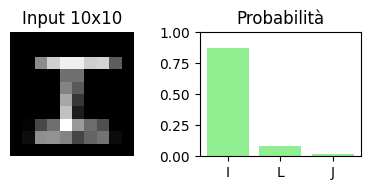

 Lettera Rilevata: 'I' (Confidenza: 87.69%)



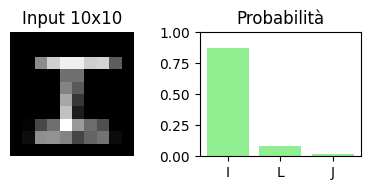

 Lettera Rilevata: 'I' (Confidenza: 87.69%)



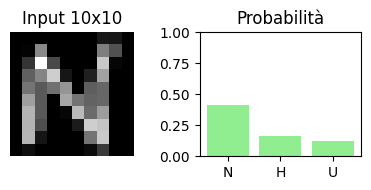

 Lettera Rilevata: 'N' (Confidenza: 41.14%)



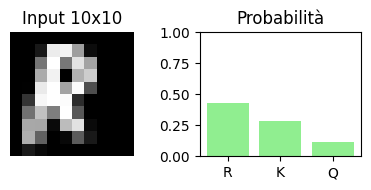

 Lettera Rilevata: 'R' (Confidenza: 43.18%)



In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import output
from IPython.display import HTML, display

# HTML & JavaScript per creare un canvas interattivo
canvas_html = """
<div style="display: flex; flex-direction: column; align-items: center;">
    <canvas id="canvas" width="200" height="200" style="border:3px solid #333; background-color:black; cursor:crosshair;"></canvas>
    <div style="margin-top: 10px;">
        <button id="clear_btn" style="padding: 8px 16px; margin-right: 10px; font-size: 14px;">Cancella</button>
        <button id="predict_btn" style="padding: 8px 16px; font-size: 14px; background-color: #4CAF50; color: white; border: none; cursor: pointer;">Riconosci</button>
    </div>
</div>

<script>
    var canvas = document.getElementById('canvas');
    var ctx = canvas.getContext('2d');
    ctx.lineWidth = 14;
    ctx.lineCap = 'round';
    ctx.strokeStyle = 'white';
    var drawing = false;

    canvas.addEventListener('mousedown', function(e) {
        drawing = true;
        ctx.beginPath();
        ctx.moveTo(e.clientX - canvas.getBoundingClientRect().left, e.clientY - canvas.getBoundingClientRect().top);
    });

    canvas.addEventListener('mousemove', function(e) {
        if (drawing) {
            ctx.lineTo(e.clientX - canvas.getBoundingClientRect().left, e.clientY - canvas.getBoundingClientRect().top);
            ctx.stroke();
        }
    });

    canvas.addEventListener('mouseup', function() { drawing = false; });
    canvas.addEventListener('mouseleave', function() { drawing = false; });

    // Supporto Touch per Mobile
    canvas.addEventListener('touchstart', function(e) {
        drawing = true;
        var touch = e.touches[0];
        ctx.beginPath();
        ctx.moveTo(touch.clientX - canvas.getBoundingClientRect().left, touch.clientY - canvas.getBoundingClientRect().top);
        e.preventDefault();
    });
    canvas.addEventListener('touchmove', function(e) {
        if (drawing) {
            var touch = e.touches[0];
            ctx.lineTo(touch.clientX - canvas.getBoundingClientRect().left, touch.clientY - canvas.getBoundingClientRect().top);
            ctx.stroke();
        }
        e.preventDefault();
    });

    document.getElementById('clear_btn').addEventListener('click', function() {
        ctx.clearRect(0, 0, canvas.width, canvas.height);
    });

    document.getElementById('predict_btn').addEventListener('click', function() {
        var dataUrl = canvas.toDataURL('image/png');
        google.colab.kernel.invokeFunction('notebook.PredictLetter10x10', [dataUrl], {});
    });
</script>
"""

def predict_letter_10x10(image_data):
    # Decodifica base64
    header, encoded = image_data.split(",", 1)
    import base64
    data = base64.b64decode(encoded)

    # Converte in immagine OpenCV
    nparr = np.frombuffer(data, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_UNCHANGED)

    # Estrae canale Alpha per i pixel disegnati
    if img.shape[2] == 4:
        gray = img[:, :, 3]
    else:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Ridimensionamento esatto a 10x10 pixel
    resized = cv2.resize(gray, (10, 10), interpolation=cv2.INTER_AREA)

    # Normalizzazione coerente con il preprocessing [0, 1]
    normalized = resized.astype(np.float32) / 255.0

    # Shape (1, 10, 10, 1)
    model_input = np.expand_dims(normalized, axis=(0, -1))

    # Predizione con il modello corretto
    predictions = model.predict(model_input, verbose=0)[0]
    class_idx = np.argmax(predictions)
    confidence = predictions[class_idx] * 100

    # Associa l'indice alla lettera (0 -> A, 25 -> Z)
    letter = chr(65 + class_idx)

    # Plot grafico di input e probabilità
    plt.figure(figsize=(4, 2))
    plt.subplot(1, 2, 1)
    plt.imshow(resized, cmap='gray')
    plt.title("Input 10x10")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    top_3_idx = np.argsort(predictions)[-3:][::-1]
    top_3_letters = [chr(65 + idx) for idx in top_3_idx]
    top_3_vals = [predictions[idx] for idx in top_3_idx]
    plt.bar(top_3_letters, top_3_vals, color='lightgreen')
    plt.ylim(0, 1)
    plt.title("Probabilità")
    plt.tight_layout()
    plt.show()

    print(f" Lettera Rilevata: '{letter}' (Confidenza: {confidence:.2f}%)\n")

# Registrazione Callback
output.register_callback('notebook.PredictLetter10x10', predict_letter_10x10)

# Display canvas
display(HTML(canvas_html))

In [ ]:
import numpy as np

# Caricamento dei nuovi pesi aggiornati
w1 = np.loadtxt('weights1.txt', dtype=np.int8).reshape(100, 32)
b1 = np.loadtxt('biases1.txt', dtype=np.int16).reshape(32)
w2 = np.loadtxt('weights2.txt', dtype=np.int8).reshape(32, 26)
b2 = np.loadtxt('biases2.txt', dtype=np.int16).reshape(26)

# Generazione del file VHDL 'mlp_weights.vhd'
with open('mlp_weights.vhd', 'w') as f:
    f.write('library IEEE;\n')
    f.write('use IEEE.STD_LOGIC_1164.ALL;\n')
    f.write('use IEEE.NUMERIC_STD.ALL;\n\n')
    f.write('package mlp_weights is\n')

    f.write('  type w1_t is array (0 to 100*32-1) of integer range -128 to 127;\n')
    f.write('  constant W1 : w1_t := (\n')
    for i, val in enumerate(w1.flatten()):
        f.write(f'    {val}')
        if i < len(w1.flatten())-1:
            f.write(',')
        if (i+1) % 16 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type b1_t is array (0 to 31) of integer range -32768 to 32767;\n')
    f.write('  constant B1 : b1_t := (\n')
    for i, val in enumerate(b1.flatten()):
        f.write(f'    {val}')
        if i < len(b1.flatten())-1:
            f.write(',')
        if (i+1) % 8 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type w2_t is array (0 to 32*26-1) of integer range -128 to 127;\n')
    f.write('  constant W2 : w2_t := (\n')
    for i, val in enumerate(w2.flatten()):
        f.write(f'    {val}')
        if i < len(w2.flatten())-1:
            f.write(',')
        if (i+1) % 16 == 0:
            f.write('\n')
    f.write('  );\n\n')

    f.write('  type b2_t is array (0 to 25) of integer range -32768 to 32767;\n')
    f.write('  constant B2 : b2_t := (\n')
    for i, val in enumerate(b2.flatten()):
        f.write(f'    {val}')
        if i < len(b2.flatten())-1:
            f.write(',')
        if (i+1) % 8 == 0:
            f.write('\n')
    f.write('  );\n')
    f.write('end package;\n')

print("mlp_weights.vhd rigenerato con i nuovi pesi del modello 10x10!")

mlp_weights.vhd rigenerato con i nuovi pesi del modello 10x10!
